In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

In [3]:
df = sns.load_dataset("iris")

print("First 5 Rows:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns)

First 5 Rows:
   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa

Dataset Shape:
(150, 5)

Column Names:
Index(['sepal_length', 'sepal_width', 'petal_length', 'petal_width',
       'species'],
      dtype='str')


In [4]:
os.makedirs("visual_report", exist_ok=True)

print("Output folder created successfully!")


Output folder created successfully!


In [5]:
numeric_columns = df.select_dtypes(include="number").columns
categorical_columns = df.select_dtypes(include="object", exclude=None).columns

print("Numeric Columns:")
print(numeric_columns)

print("\nCategorical Columns:")
print(categorical_columns)

Numeric Columns:
Index(['sepal_length', 'sepal_width', 'petal_length', 'petal_width'], dtype='str')

Categorical Columns:
Index(['species'], dtype='str')


C:\Users\X280\AppData\Local\Temp\ipykernel_17624\2595835091.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(include="object", exclude=None).columns


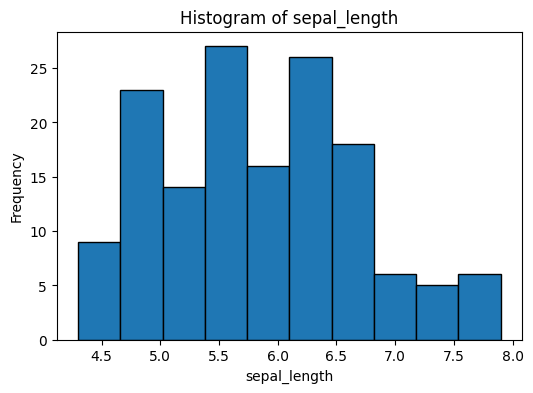

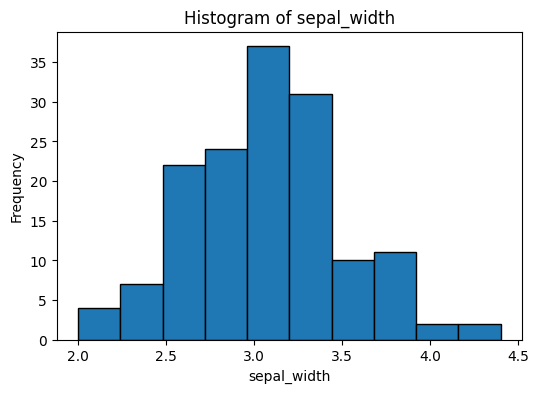

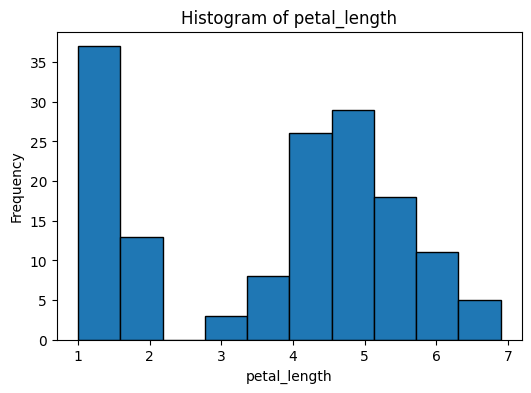

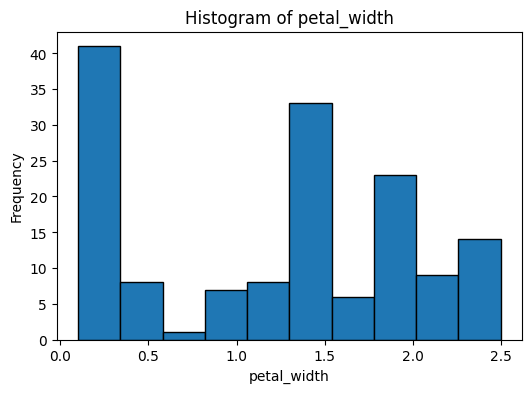

In [6]:
for col in numeric_columns:
    plt.figure(figsize=(6, 4))

    plt.hist(df[col], bins=10, edgecolor="black")

    plt.title("Histogram of " + col)
    plt.xlabel(col)
    plt.ylabel("Frequency")

    plt.savefig("visual_report/histogram_" + col + ".png")
    plt.show()
    plt.close()

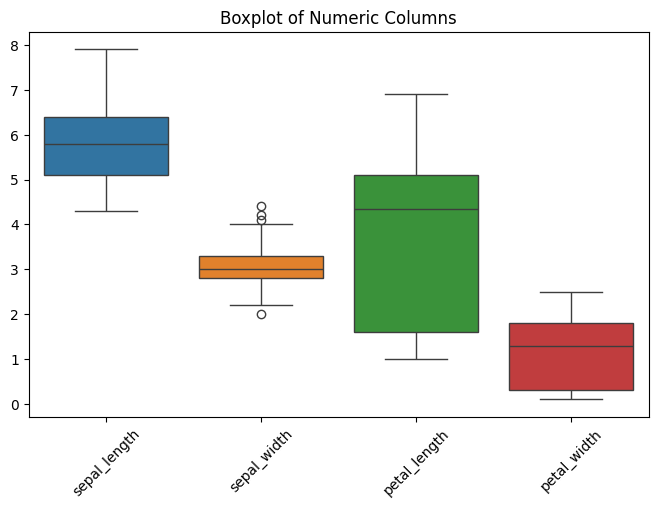

In [7]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df[numeric_columns])

plt.title("Boxplot of Numeric Columns")
plt.xticks(rotation=45)

plt.savefig("visual_report/boxplot_outliers.png")
plt.show()
plt.close()

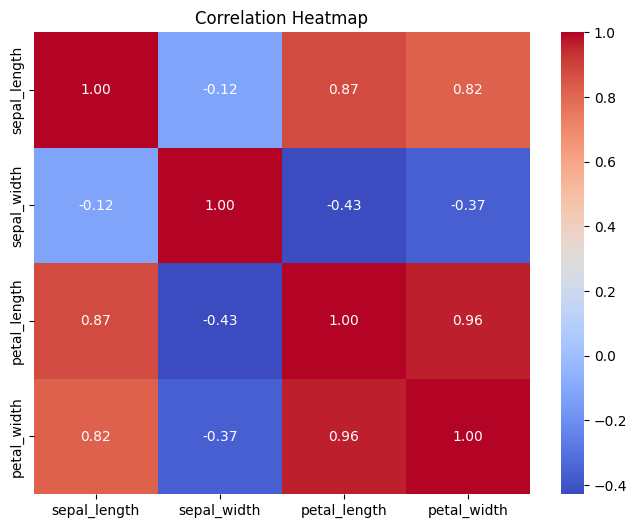

In [8]:
plt.figure(figsize=(8, 6))

correlation = df[numeric_columns].corr()

sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Heatmap")

plt.savefig("visual_report/correlation_heatmap.png")
plt.show()
plt.close()

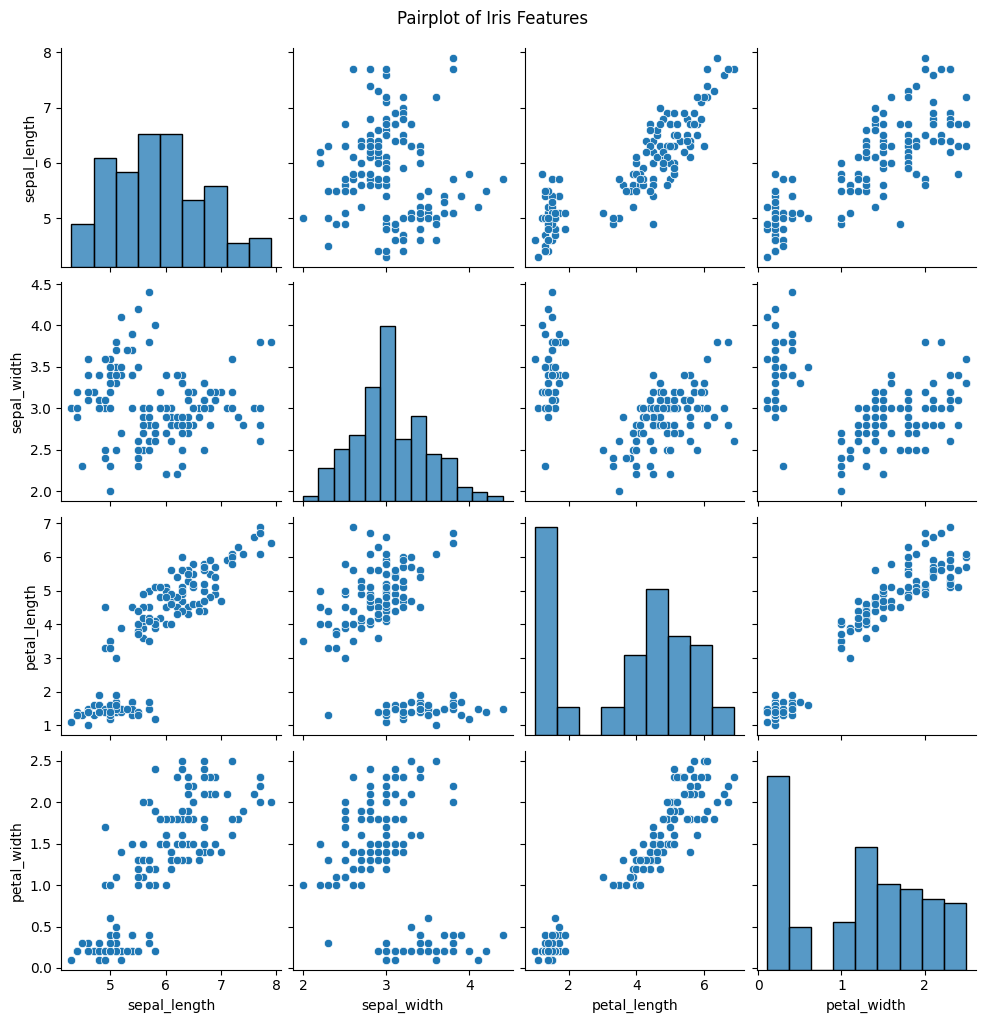

In [9]:
pair = sns.pairplot(df, vars=numeric_columns)

pair.fig.suptitle("Pairplot of Iris Features", y=1.02)

pair.savefig("visual_report/pairplot.png")
plt.show()
plt.close()

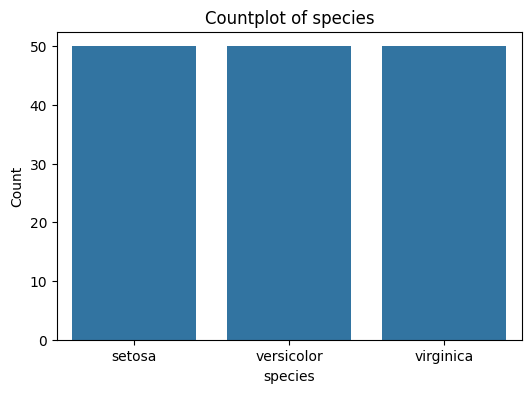

In [11]:
for col in categorical_columns:
    plt.figure(figsize=(6, 4))

    sns.countplot(data=df, x=col)

    plt.title("Countplot of " + col)
    plt.xlabel(col)
    plt.ylabel("Count")

    plt.savefig("visual_report/countplot_" + col + ".png")
    plt.show()
    plt.close()

In [12]:
files = os.listdir("visual_report")

print("Saved Plot Files:")

for file in files:
    print(file)

print("\nTotal PNG Files:", len(files))

Saved Plot Files:
boxplot_outliers.png
correlation_heatmap.png
countplot_species.png
histogram_petal_length.png
histogram_petal_width.png
histogram_sepal_length.png
histogram_sepal_width.png
pairplot.png

Total PNG Files: 8
